# Phase 2: nhánh luật trên feature bộ phận × thời gian

Code ở `zeroshot/nesy/phase2.py` (mô hình), `features.py` (trích feature) và `phase1.py` (cách đánh giá dùng chung).

Mỗi split chạy 3 mô hình, cùng seed nên cùng tập validation:
- `emb`: nhánh embedding trên feature đã pool (giống phase 1).
- `rule1`: nhánh luật của phase 1 (feature đã pool).
- `rule2`: nhánh luật mới. Primitive được dự đoán theo bộ phận × thời gian, kèm luật thứ tự và ràng buộc loại trừ.

Sau đó ghép `emb + β·rule` sau khi train, với β chọn trên val. Mỗi kết quả có 2 cột:
- **clean**: epoch và γ chọn trên val.
- **best-on-test** (`_bt`): lấy max trên test, cách các paper báo cáo.

In [2]:
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')

import os, sys, gc, subprocess, importlib
import numpy as np, pandas as pd, torch

DRIVE_DIR   = '/content/drive/MyDrive/BaoHuy/zeroshot'
WEIGHTS_DIR = f'{DRIVE_DIR}/shiftgcn_weights'
SKEL = {'ntu60':  '/content/drive/MyDrive/BaoHuy/KLTN_Huy-Nhu/NTU60_CS.npz',
        'ntu120': '/content/drive/MyDrive/BaoHuy/KLTN_Huy-Nhu/NTU120_CSub.npz'}
TEXT_CACHE = f'{DRIVE_DIR}/phase1/text_proto.npz'    # tạo bởi phase1.ipynb (cell text)
OUT_DIR    = f'{DRIVE_DIR}/phase2'
# Cache feature bộ phận × thời gian (fp16): ~3.4 GB / split NTU60, ~7 GB / split NTU120.
# Mặc định để trên ổ local của Colab (mất khi hết phiên, trích lại ~45 phút cho 4 split).
# Drive còn chỗ thì đổi sang f'{DRIVE_DIR}/cache_p2' để lần sau khỏi trích.
CACHE_DIR  = '/content/cache_p2'
os.makedirs(OUT_DIR, exist_ok=True)

REPO = '/content/thesis'
if not os.path.exists(REPO):
    try:
        from google.colab import userdata
        tok = userdata.get('GH_TOKEN')
    except Exception:
        tok = None
    url = f'https://{tok}@github.com/NguyenBaoHuy05/thesis.git' if tok else 'https://github.com/NguyenBaoHuy05/thesis.git'
    subprocess.run(['git', 'clone', '-q', url, REPO], check=True)
else:
    subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
!git -C {REPO} log -1 --format='%h %s'
NESY = f'{REPO}/zeroshot/nesy'
if NESY not in sys.path:
    sys.path.insert(0, NESY)
import phase1, features, phase2
for m in (phase1, features, phase2):
    importlib.reload(m)
TASKS = list(phase1.UNSEEN)

Mounted at /content/drive
38f754b Add phase 2 (part x time rule branch) and best-on-test reporting


In [3]:
prims, names, R, imp = phase1.load_kg(f'{REPO}/zeroshot/kg_rules.json', f'{REPO}/zeroshot/primitive.json')
struct = phase2.load_kg_structure(f'{REPO}/zeroshot/kg_rules.json', f'{REPO}/zeroshot/primitive.json')
print(f'{len(prims)} primitive | {len(imp)} ràng buộc kéo theo | {len(struct["excl_pairs"])} cặp loại trừ')
print('nhóm loại trừ dùng:', struct['excl_used'])
print('bỏ qua (tay/cánh tay, hai bên có thể khác nhau):', struct['excl_skipped'])
print(f'{len(struct["seqs"])} lớp có luật thứ tự')
seq_cls = {c for c, _ in struct['seqs']}
for task in TASKS:
    u = phase1.UNSEEN[task]
    print(f'  {task}: lớp unseen có luật thứ tự:', [names[c] for c in u if c in seq_cls])

tp = np.load(TEXT_CACHE)
text_proto = tp['per_src'].mean(1)
text_proto /= np.linalg.norm(text_proto, axis=1, keepdims=True)
print('text_proto', text_proto.shape, list(tp['sources']))

71 primitive | 13 ràng buộc kéo theo | 16 cặp loại trừ
nhóm loại trừ dùng: ['body_posture', 'body_vertical_motion', 'head_oscillation', 'inter_distance_change', 'inter_orientation', 'kick_direction', 'trunk_sagittal']
bỏ qua (tay/cánh tay, hai bên có thể khác nhau): ['elbow_angle', 'hand_contact_zone', 'hand_height', 'hand_oscillation', 'hand_reach_speed', 'thumb_orientation', 'upper_arm_direction']
26 lớp có luật thứ tự
  ntu60_xsub_seen55_unseen5: lớp unseen có luật thứ tự: ['put on a hat/cap']
  ntu60_xsub_seen48_unseen12: lớp unseen có luật thứ tự: ['wear a shoe', 'falling', 'pushing other person']
  ntu120_xsub_seen110_unseen10: lớp unseen có luật thứ tự: ['wear jacket', 'put something into a bag']
  ntu120_xsub_seen96_unseen24: lớp unseen có luật thứ tự: ['take off a shoe', 'take off glasses', 'take off a hat/cap', 'apply cream on face', 'take off bag', 'throw up cap/hat']
text_proto (120, 768) [np.str_('name'), np.str_('spatial_cg'), np.str_('spatial_mg'), np.str_('spatial_fg'),

In [4]:
# Trích pooled (256) + cube (8 bộ phận × 16 thời gian × 256) bằng encoder Neuron đóng băng.
# Mỗi split dùng weights riêng (pretrain trên lớp seen của split đó). Có cache rồi thì bỏ qua.
importlib.reload(features)
for ds in ('ntu60', 'ntu120'):
    tasks = [t for t in TASKS if t.startswith(ds + '_')]
    if all(os.path.exists(features.cache_paths(CACHE_DIR, t, 'test')['label']) for t in tasks):
        print(ds, ': cache có sẵn'); continue
    skel = dict(np.load(SKEL[ds]))       # đọc một lần cho cả dataset (7-20 GB RAM)
    for t in tasks:
        features.extract_split(skel, WEIGHTS_DIR, t, phase1.UNSEEN[t], CACHE_DIR)
    del skel; gc.collect()
!du -sh {CACHE_DIR}

/content/thesis/zeroshot/nesy/model/shiftgcn_match.py:94: FutureWarning: `nn.init.constant` is now deprecated in favor of `nn.init.constant_`.
  nn.init.constant(self.Linear_bias, 0)
/content/thesis/zeroshot/nesy/model/shiftgcn_match.py:97: FutureWarning: `nn.init.constant` is now deprecated in favor of `nn.init.constant_`.
  nn.init.constant(self.Feature_Mask, 0)
/content/thesis/zeroshot/nesy/model/shiftgcn_match.py:22: FutureWarning: `nn.init.kaiming_normal` is now deprecated in favor of `nn.init.kaiming_normal_`.
  nn.init.kaiming_normal(conv.weight, mode='fan_out')
/content/thesis/zeroshot/nesy/model/shiftgcn_match.py:23: FutureWarning: `nn.init.constant` is now deprecated in favor of `nn.init.constant_`.
  nn.init.constant(conv.bias, 0)
/content/thesis/zeroshot/nesy/model/shiftgcn_match.py:27: FutureWarning: `nn.init.constant` is now deprecated in favor of `nn.init.constant_`.
  nn.init.constant(bn.weight, scale)
/content/thesis/zeroshot/nesy/model/shiftgcn_match.py:28: FutureWarn

[ntu60_xsub_seen55_unseen5] train: 36758 mẫu, 224s
[ntu60_xsub_seen55_unseen5] test: 16487 mẫu, 100s
[ntu60_xsub_seen48_unseen12] train: 32070 mẫu, 194s
[ntu60_xsub_seen48_unseen12] test: 16487 mẫu, 100s
[ntu120_xsub_seen110_unseen10] train: 57767 mẫu, 349s
[ntu120_xsub_seen110_unseen10] test: 50919 mẫu, 308s
[ntu120_xsub_seen96_unseen24] train: 50141 mẫu, 303s
[ntu120_xsub_seen96_unseen24] test: 50919 mẫu, 308s
20G	/content/cache_p2


In [5]:
for m in (phase1, phase2):
    importlib.reload(m)
SEEDS = [0]
TRAIN_KW = dict(epochs=30, warmup=5, lr=1e-3, wd=1e-4, bs=256)
POOLED_KW = dict(hidden=1024, dropout=0.3, beta_init=5.0, lam_prim=1.0, lam_cons=1.0)
PT_KW = dict(d=256, n_blocks=2, dropout=0.2, tau=1.0, beta_init=5.0, lam_prim=1.0, lam_cons=1.0, lam_excl=1.0)
ABLATE_SEQ = False                 # True: thêm rule2 không có luật thứ tự (ablation)
RES_CSV = f'{OUT_DIR}/results.csv'

results, hists, scores = [], {}, {}
def record(task, name, seed, out):
    res, hist, sc = out
    results.append(res)
    hists[(task, name, seed)], scores[(task, name, seed)] = hist, sc
    pd.DataFrame(results).to_csv(RES_CSV, index=False)

for task in TASKS:
    for seed in SEEDS:
        data = features.load_cache(CACHE_DIR, task, kind='pooled')
        for mode, name in (('emb', 'emb'), ('rule', 'rule1')):
            make = phase1.make_pooled(mode, text_proto, R, imp, **POOLED_KW)
            record(task, name, seed, phase1.run_split(data, task, make, name=name, seed=seed, train_kw=TRAIN_KW))
        del data
        data = features.load_cache(CACHE_DIR, task, kind='cube')
        variants = [('rule2', {})] + ([('rule2_noseq', dict(use_seq=False))] if ABLATE_SEQ else [])
        for name, extra in variants:
            make = phase2.make_parttime(R, imp, struct, **PT_KW, **extra)
            record(task, name, seed, phase1.run_split(data, task, make, name=name, seed=seed, train_kw=TRAIN_KW))
        del data; gc.collect(); torch.cuda.empty_cache()

df = pd.DataFrame(results)
show = ['task', 'model', 'seed', 'epoch_val', 'val_zsl', 'zsl', 'zsl_best_test', 'gzsl_H', 'H_best_test']
display(df[show].round(4))

/content/thesis/zeroshot/nesy/features.py:106: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  t[i:i + chunk] = torch.from_numpy(np.ascontiguousarray(arr[i:i + chunk])).to(device)


[ntu60_xsub_seen55_unseen5 emb seed0] val: best ZSL 0.7696 @ep3, H 0.7542, last ZSL 0.7289
[ntu60_xsub_seen55_unseen5 emb seed0] test clean: ZSL 0.7602 H 0.6113 | best-on-test: ZSL 0.7675 H 0.6473
[ntu60_xsub_seen55_unseen5 rule1 seed0] val: best ZSL 0.7597 @ep8, H 0.5503, last ZSL 0.7182


/content/thesis/zeroshot/nesy/phase1.py:335: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  res['beta'] = float(model.log_beta.exp())


[ntu60_xsub_seen55_unseen5 rule1 seed0] test clean: ZSL 0.6484 H 0.5700 | best-on-test: ZSL 0.6630 H 0.5847
[ntu60_xsub_seen55_unseen5 rule2 seed0] val: best ZSL 0.8237 @ep11, H 0.5694, last ZSL 0.7839
[ntu60_xsub_seen55_unseen5 rule2 seed0] test clean: ZSL 0.4057 H 0.3477 | best-on-test: ZSL 0.5051 H 0.4426
[ntu60_xsub_seen48_unseen12 emb seed0] val: best ZSL 0.4763 @ep1, H 0.5748, last ZSL 0.4221
[ntu60_xsub_seen48_unseen12 emb seed0] test clean: ZSL 0.4676 H 0.5026 | best-on-test: ZSL 0.4719 H 0.5063
[ntu60_xsub_seen48_unseen12 rule1 seed0] val: best ZSL 0.2253 @ep6, H 0.2674, last ZSL 0.1513
[ntu60_xsub_seen48_unseen12 rule1 seed0] test clean: ZSL 0.1762 H 0.1993 | best-on-test: ZSL 0.2163 H 0.2436
[ntu60_xsub_seen48_unseen12 rule2 seed0] val: best ZSL 0.2373 @ep12, H 0.2393, last ZSL 0.2015
[ntu60_xsub_seen48_unseen12 rule2 seed0] test clean: ZSL 0.1115 H 0.1212 | best-on-test: ZSL 0.2145 H 0.1614
[ntu120_xsub_seen110_unseen10 emb seed0] val: best ZSL 0.6914 @ep14, H 0.7280, last 

,task,model,seed,epoch_val,val_zsl,zsl,zsl_best_test,gzsl_H,H_best_test
0,ntu60_xsub_seen55_unseen5,emb,0,3,0.7696,0.7602,0.7675,0.6113,0.6473
1,ntu60_xsub_seen55_unseen5,rule1,0,8,0.7597,0.6484,0.6630,0.5700,0.5847
2,ntu60_xsub_seen55_unseen5,rule2,0,11,0.8237,0.4057,0.5051,0.3477,0.4426
3,ntu60_xsub_seen48_unseen12,emb,0,1,0.4763,0.4676,0.4719,0.5026,0.5063
4,ntu60_xsub_seen48_unseen12,rule1,0,6,0.2253,0.1762,0.2163,0.1993,0.2436
5,ntu60_xsub_seen48_unseen12,rule2,0,12,0.2373,0.1115,0.2145,0.1212,0.1614
6,ntu120_xsub_seen110_unseen10,emb,0,14,0.6914,0.5881,0.6710,0.5680,0.5963
7,ntu120_xsub_seen110_unseen10,rule1,0,6,0.4724,0.1963,0.3361,0.1941,0.2047
8,ntu120_xsub_seen110_unseen10,rule2,0,12,0.3984,0.3822,0.3895,0.3669,0.4165
9,ntu120_xsub_seen96_unseen24,emb,0,16,0.4334,0.5413,0.5736,0.4768,0.5020


In [6]:
# Ghép emb + beta * rule (beta chọn trên val). So rule1 (phase 1) với rule2 (phase 2).
importlib.reload(phase1)
rows, tables = [], {}
rules = ['rule1', 'rule2'] + (['rule2_noseq'] if ABLATE_SEQ else [])
for task in TASKS:
    for seed in SEEDS:
        for rname in rules:
            chosen, table = phase1.posthoc_fusion(scores[(task, 'emb', seed)], scores[(task, rname, seed)])
            t = pd.DataFrame(table)
            tables[(task, rname, seed)] = t
            e0 = t[t.beta == 0].iloc[0]
            rows.append(dict(task=task, seed=seed, rule=rname, beta_val=chosen['beta'],
                             zsl_emb=e0.zsl, zsl_fused=chosen['zsl'], gain=chosen['zsl'] - e0.zsl,
                             zsl_emb_bt=e0.zsl_best_test, zsl_fused_bt=chosen['zsl_best_test'],
                             gain_bt=chosen['zsl_best_test'] - e0.zsl_best_test,
                             H_emb=e0.gzsl_H, H_fused=chosen['gzsl_H'],
                             H_emb_bt=e0.H_best_test, H_fused_bt=chosen['H_best_test']))
ph = pd.DataFrame(rows).round(4)
ph.to_csv(f'{OUT_DIR}/posthoc_fusion.csv', index=False)
print('_bt = best-on-test (cách các paper báo cáo); không hậu tố = clean (chọn trên val)')
display(ph)

_bt = best-on-test (cách các paper báo cáo); không hậu tố = clean (chọn trên val)


,task,seed,rule,beta_val,zsl_emb,zsl_fused,gain,zsl_emb_bt,zsl_fused_bt,gain_bt,H_emb,H_fused,H_emb_bt,H_fused_bt
0,ntu60_xsub_seen55_unseen5,0,rule1,0.50,0.7602,0.7500,-0.0102,0.7675,0.7668,-0.0007,0.6113,0.6575,0.6473,0.6862
1,ntu60_xsub_seen55_unseen5,0,rule2,1.00,0.7602,0.6747,-0.0855,0.7675,0.7025,-0.0651,0.6113,0.6363,0.6473,0.6670
2,ntu60_xsub_seen48_unseen12,0,rule1,0.20,0.4676,0.3981,-0.0696,0.4719,0.4251,-0.0468,0.5026,0.4308,0.5063,0.4478
3,ntu60_xsub_seen48_unseen12,0,rule2,0.01,0.4676,0.4613,-0.0064,0.4719,0.4731,0.0012,0.5026,0.4954,0.5063,0.5021
4,ntu120_xsub_seen110_unseen10,0,rule1,1.00,0.5881,0.5491,-0.0391,0.6710,0.5905,-0.0805,0.5680,0.5684,0.5963,0.5582
5,ntu120_xsub_seen110_unseen10,0,rule2,0.02,0.5881,0.5881,0.0000,0.6710,0.6707,-0.0002,0.5680,0.5697,0.5963,0.5971
6,ntu120_xsub_seen96_unseen24,0,rule1,1.00,0.5413,0.5947,0.0534,0.5736,0.5676,-0.0060,0.4768,0.5052,0.5020,0.5439
7,ntu120_xsub_seen96_unseen24,0,rule2,0.50,0.5413,0.5980,0.0566,0.5736,0.5915,0.0179,0.4768,0.5178,0.5020,0.5371


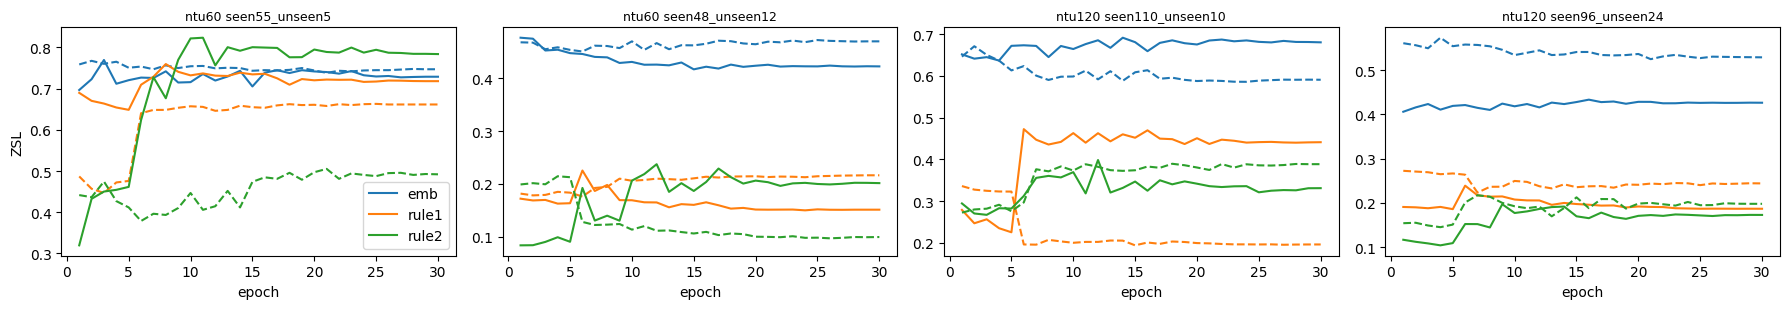

In [7]:
# Nét liền: val ZSL (chọn epoch). Nét đứt: test ZSL của lần train cuối.
import matplotlib.pyplot as plt
names_m = ['emb', 'rule1', 'rule2']
fig, axes = plt.subplots(1, len(TASKS), figsize=(4.5 * len(TASKS), 3.2))
for ax, task in zip(axes, TASKS):
    for i, n in enumerate(names_m):
        h = hists.get((task, n, SEEDS[0]))
        if h:
            ax.plot([r['epoch'] for r in h['val']], [r['val_zsl'] for r in h['val']], color=f'C{i}', label=n)
            ax.plot([r['epoch'] for r in h['test']], [r['test_zsl'] for r in h['test']], color=f'C{i}', ls='--')
    ax.set_title(task.replace('_xsub_', ' '), fontsize=9)
    ax.set_xlabel('epoch')
axes[0].set_ylabel('ZSL')
axes[0].legend()
plt.tight_layout()
plt.show()

## Đọc kết quả

- **`rule2` so với `rule1`** (bảng `run`, cột `zsl`): đây là cái lợi của feature bộ phận × thời gian và luật thứ tự đối với riêng nhánh luật.
- **`gain` của `rule2` so với của `rule1`** (bảng `posthoc`): đây là phần KG đóng góp thêm vào nhánh embedding. Đây là con số chính.
- **`_bt`**: số để đặt cạnh bảng của các paper. Trong luận văn ghi rõ hai cách tính.
- Muốn biết luật thứ tự giúp bao nhiêu thì đặt `ABLATE_SEQ = True`.

Gửi mình hai bảng `run` và `posthoc`.